### 1. Download the Road Damage Dataset

In [ ]:
# garbage prediction dataset import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

# poor drainage dataset
import kagglehub

# Download latest version
path = kagglehub.dataset_download("myprojectdata/drainage-and-waterbody-datasetchennai")

print("Path to dataset files:", path)

### 1.1 Process and Combine New Datasets (Garbage & Drainage)

In [14]:
import os
import pandas as pd
import kagglehub

# Dynamically download/resolve dataset paths using kagglehub to get the absolute active paths
garbage_path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
drainage_path = kagglehub.dataset_download("myprojectdata/drainage-and-waterbody-datasetchennai")

print("Resolved Garbage path:", garbage_path)
print("Resolved Drainage path:", drainage_path)

new_image_paths = []
new_labels = []

def find_images(dir_path):
    images = []
    if os.path.exists(dir_path):
        for root, _, files in os.walk(dir_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    images.append(os.path.join(root, file))
    return images

# Find and label garbage images
garbage_images = find_images(garbage_path)
for img in garbage_images:
    new_image_paths.append(img)
    new_labels.append('garbage')

# Find and label drainage images
drainage_images = find_images(drainage_path)
for img in drainage_images:
    new_image_paths.append(img)
    new_labels.append('poor_drainage')

new_df = pd.DataFrame({'image_path': new_image_paths, 'label': new_labels})
print(f"New dataset elements loaded: {len(new_df)}")
if len(new_df) > 0:
    print(new_df['label'].value_counts())

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.


100%|██████████| 17.1M/17.1M [00:00<00:00, 96.5MB/s]

Extracting files...


Resolved Garbage path: /kaggle/input/garbage-classification-v2
Resolved Drainage path: /root/.cache/kagglehub/datasets/myprojectdata/drainage-and-waterbody-datasetchennai/versions/1
New dataset elements loaded: 36977
label
garbage          36777
poor_drainage      200
Name: count, dtype: int64


### 2.2 Combine and Recreate Data Generators with 5 Classes

In [15]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import json
import pandas as pd
import kagglehub

# Dynamically resolve the road damage dataset path
active_road_path = kagglehub.dataset_download("lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes")
print("Active Road Damage Dataset Path:", active_road_path)

annotations_path = os.path.join(active_road_path, "data", "annotations_coco.json")
images_dir = os.path.join(active_road_path, "data", "images")

with open(annotations_path, 'r') as f:
    coco_data = json.load(f)

categories = {cat['id']: cat['name'] for cat in coco_data['categories']}
images = {img['id']: img['file_name'] for img in coco_data['images']}

img_to_categories = {img_id: [] for img_id in images.keys()}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    cat_id = ann['category_id']
    if img_id in img_to_categories:
        img_to_categories[img_id].append(categories[cat_id])

image_paths, labels = [], []
for img_id, file_name in images.items():
    full_path = os.path.join(images_dir, file_name)
    if os.path.exists(full_path):
        cats = img_to_categories[img_id]
        label = cats[0] if len(cats) > 0 else 'normal'
        image_paths.append(full_path)
        labels.append(label)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# Combine original df with the new df loaded in the previous step
combined_df = pd.concat([df, new_df], ignore_index=True)
print("Combined Dataset Class Distribution:")
print(combined_df['label'].value_counts())

# Split combined dataset
train_df, val_df = train_test_split(combined_df, test_size=0.2, random_state=42, stratify=combined_df['label'])

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

100%|██████████| 185M/185M [00:01<00:00, 97.2MB/s]

Extracting files...


Active Road Damage Dataset Path: /root/.cache/kagglehub/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/versions/4
Combined Dataset Class Distribution:
label
garbage          36777
crack             1002
manhole            541
pothole            466
poor_drainage      200
Name: count, dtype: int64
Found 31188 validated image filenames belonging to 5 classes.
Found 7798 validated image filenames belonging to 5 classes.


### 3.2 Initialize and Compile the Model for 5 Classes

In [16]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Safely load the number of classes from the active generator
num_classes = len(train_generator.class_indices)
print("New Target Classes:", train_generator.class_indices)

# Build the base MobileNetV2 transfer learning model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

# Configure sequence mapping matching 5 outputs
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

New Target Classes: {'crack': 0, 'garbage': 1, 'manhole': 2, 'poor_drainage': 3, 'pothole': 4}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,205 (9.87 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 4.2 Train Head and Fine-tune on the Expanded Dataset

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("Phase 1: Training the custom classification head...")
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    callbacks=[early_stopping]
)

print("Phase 2: Fine-tuning the network...")
base_model.trainable = True
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    callbacks=[early_stopping]
)

Phase 1: Training the custom classification head...
Epoch 1/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 616s 618ms/step - accuracy: 0.9685 - loss: 0.0787 - val_accuracy: 0.9764 - val_loss: 0.0530
Epoch 2/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 443s 455ms/step - accuracy: 0.9733 - loss: 0.0573 - val_accuracy: 0.9761 - val_loss: 0.0507
Epoch 3/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 465s 477ms/step - accuracy: 0.9730 - loss: 0.0566 - val_accuracy: 0.9750 - val_loss: 0.0513
Epoch 4/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 455s 467ms/step - accuracy: 0.9739 - loss: 0.0550 - val_accuracy: 0.9747 - val_loss: 0.0515
Epoch 5/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 459s 471ms/step - accuracy: 0.9751 - loss: 0.0549 - val_accuracy: 0.9751 - val_loss: 0.0518
Phase 2: Fine-tuning the network...
Epoch 1/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 585s 539ms/step - accuracy: 0.9731 - loss: 0.0611 - val_accuracy: 0.9753 - val_loss: 0.0537
Epoch 2/5
975/975 ━━━━━━━━━━━━━━━━━━━━ 482s 494ms/step - accuracy: 0.9760 - loss: 0.0523 - val_accuracy: 0.9756 - val_loss: 0.

### 5.0 Save and Export the Retrained 5-Class Model

In [18]:
import numpy as np
import tensorflow as tf
from google.colab import files

# 1. Define the 5 class labels mapping based on our new generator mapping
class_names_5class = list(train_generator.class_indices.keys())
print("Class labels mapped sequentially:", class_names_5class)

# 2. Save the retrained model to disk
export_model_path = "road_damage_5class_model.keras"
model.save(export_model_path)
print(f"Model successfully saved to '{export_model_path}'")

# 3. Trigger automatic download of the saved model from Colab
print("Initiating download...")
files.download(export_model_path)


Class labels mapped sequentially: ['crack', 'garbage', 'manhole', 'poor_drainage', 'pothole']
Model successfully saved to 'road_damage_5class_model.keras'
Initiating download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import kagglehub
import os

# Download latest version of the road damage dataset
path = kagglehub.dataset_download("lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes")
print("Path to dataset files:", path)

# List the directory structure to see how images are organized
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subfiles = files[:3]
    for f in subfiles:
        print(f"{indent}    {f}")
    if len(files) > 3:
        print(f"{indent}    ... and {len(files) - 3} more files")

Using Colab cache for faster access to the 'road-damage-dataset-potholes-cracks-and-manholes' dataset.
Path to dataset files: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes
road-damage-dataset-potholes-cracks-and-manholes/
    data/
        COCO-conversion-script.py
        annotations_coco.json
        README.md
        ... and 1 more files
        labels/
            vlcsnap-2025-02-19-14h18m48s452.txt
            vlcsnap-2025-02-19-14h21m29s062.txt
            vlcsnap_2025-03-16-15h14m35s770.txt
            ... and 2006 more files
        images/
            vlcsnap-2025-02-19-15h10m43s692.jpg
            vlcsnap-2025-02-18-23h30m34s296.jpg
            vlcsnap-2025-02-19-14h12m25s165.jpg
            ... and 2006 more files
        labels-YOLO/
            vlcsnap-2025-02-19-14h18m48s452.txt
            vlcsnap-2025-02-19-14h21m29s062.txt
            vlcsnap_2025-03-16-15h14m35s770.txt
            ... and 2006 more files


### 2. Prepare Data Generators and Preprocess Images
We will dynamically scan the dataset directory, build a dataframe of image paths and labels, and create training and validation generators using TensorFlow.

In [ ]:
import os
import json
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

# Locate the COCO annotation file
annotations_path = os.path.join(path, "data", "annotations_coco.json")
images_dir = os.path.join(path, "data", "images")

with open(annotations_path, 'r') as f:
    coco_data = json.load(f)

# Map category IDs to category names
categories = {cat['id']: cat['name'] for cat in coco_data['categories']}
print("Detected categories in dataset:", categories)

# Map image IDs to file names
images = {img['id']: img['file_name'] for img in coco_data['images']}

# Construct a dataset associating image filenames with their annotations/categories
# Note: Each image can contain multiple annotations. For classification, we will assign
# the primary class or fallback to 'normal' if there are no annotations.
img_to_categories = {img_id: [] for img_id in images.keys()}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    cat_id = ann['category_id']
    if img_id in img_to_categories:
        img_to_categories[img_id].append(categories[cat_id])

# Create lists of paths and labels
image_paths = []
labels = []

for img_id, file_name in images.items():
    full_path = os.path.join(images_dir, file_name)
    if os.path.exists(full_path):
        cats = img_to_categories[img_id]
        # Assign the first detected annotation category, or 'normal/background' if empty
        label = cats[0] if len(cats) > 0 else 'normal'
        image_paths.append(full_path)
        labels.append(label)

df = pd.DataFrame({'image_path': image_paths, 'label': labels})
print(f"Total mapped images found: {len(df)}")
print(df['label'].value_counts())

# Split into Train and Validation sets (80% / 20%)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

# Image configurations
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Data Augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Detected categories in dataset: {0: 'pothole', 1: 'crack', 2: 'manhole'}
Total mapped images found: 2009
label
crack      1002
manhole     541
pothole     466
Name: count, dtype: int64
Found 1607 validated image filenames belonging to 3 classes.
Found 402 validated image filenames belonging to 3 classes.


### 3. Build a Transfer Learning Model with MobileNetV2
MobileNetV2 pre-trained on ImageNet is highly accurate and lightweight, making it excellent for classification tasks on custom datasets.

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

num_classes = len(train_generator.class_indices)

# Load pre-trained MobileNetV2 base
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base layers initially

# Add custom classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 4. Train the Model
We will use EarlyStopping to automatically stop training once validation loss starts rising to guarantee the best possible final accuracy.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 58s 902ms/step - accuracy: 0.4692 - loss: 1.1277 - val_accuracy: 0.5124 - val_loss: 0.9857
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 506ms/step - accuracy: 0.5078 - loss: 0.9904 - val_accuracy: 0.5199 - val_loss: 0.9942
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 25s 497ms/step - accuracy: 0.5184 - loss: 0.9891 - val_accuracy: 0.5323 - val_loss: 0.9699
Epoch 4/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 25s 497ms/step - accuracy: 0.5445 - loss: 0.9667 - val_accuracy: 0.5572 - val_loss: 0.9532
Epoch 5/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 509ms/step - accuracy: 0.5376 - loss: 0.9671 - val_accuracy: 0.5547 - val_loss: 0.9567
Epoch 6/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 517ms/step - accuracy: 0.5457 - loss: 0.9494 - val_accuracy: 0.5448 - val_loss: 0.9725
Epoch 7/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 27s 531ms/step - accuracy: 0.5588 - loss: 0.9333 - val_accuracy: 0.5597 - val_loss: 0.9488
Epoch 8/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 516ms/step - accuracy: 0.5551 - loss: 0.9381 - val_accu

### 5. Fine-Tuning for Even Higher Accuracy
Once the head is stable, we unfreeze the top layers of MobileNetV2 to fine-tune them with a very low learning rate.

In [ ]:
# Unfreeze base model for fine-tuning
base_model.trainable = True

# Recompile with a very low learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5439 - loss: 0.9675 - val_accuracy: 0.5597 - val_loss: 0.9215
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 513ms/step - accuracy: 0.5333 - loss: 0.9456 - val_accuracy: 0.5622 - val_loss: 0.9201
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 28s 548ms/step - accuracy: 0.5569 - loss: 0.9302 - val_accuracy: 0.5547 - val_loss: 0.9258
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 28s 552ms/step - accuracy: 0.5582 - loss: 0.9285 - val_accuracy: 0.5498 - val_loss: 0.9231
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 27s 535ms/step - accuracy: 0.5600 - loss: 0.9139 - val_accuracy: 0.5672 - val_loss: 0.9200
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 512ms/step - accuracy: 0.5644 - loss: 0.9098 - val_accuracy: 0.5572 - val_loss: 0.9245
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 512ms/step - accuracy: 0.5769 - loss: 0.8814 - val_accuracy: 0.5697 - val_loss: 0.9233
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 27s 520ms/step - accuracy: 0.5899 - loss: 0.8838 - val_accura

### 6. Evaluate and Plot Performance Results
Run this cell after both training phases have completed to visualize the training and validation trends.

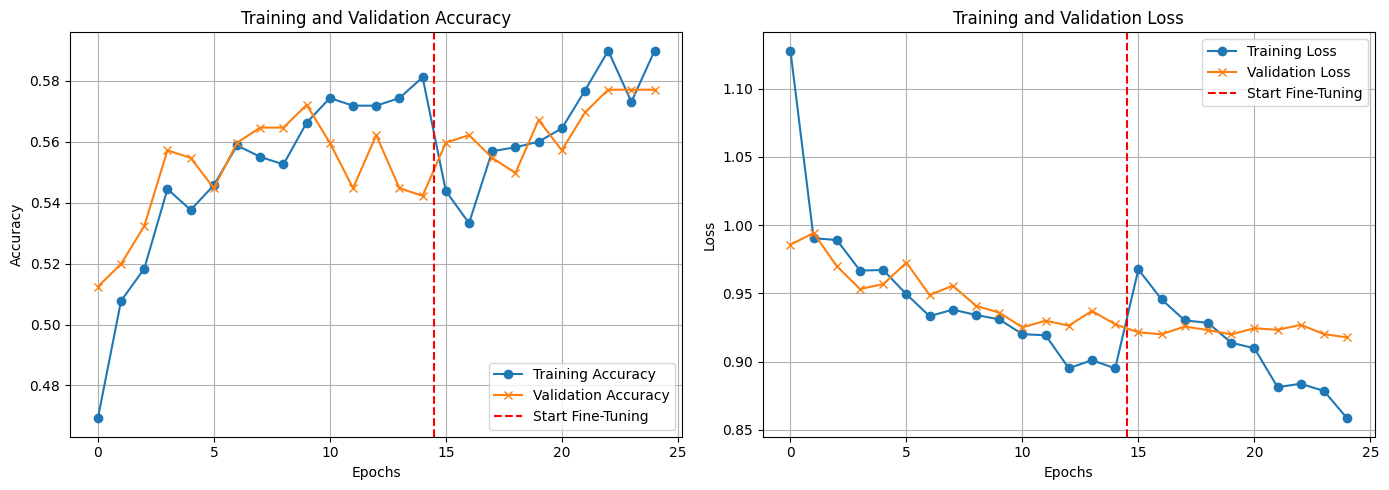

In [ ]:
import matplotlib.pyplot as plt

# Safely check if training histories exist in the notebook's memory
has_history = 'history' in locals() or 'history' in globals()
has_history_fine = 'history_fine' in locals() or 'history_fine' in globals()

if not has_history:
    print("Error: 'history' not found. Please run the initial training cell (64a0081c) first!")
elif not has_history_fine:
    print("Warning: 'history_fine' not found. Plotting initial training results only. Run the fine-tuning cell (ee188610) to get full results.")

    # Plot only initial training stage
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='x')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='x')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()
else:
    # Combine metrics across both training stages
    acc = history.history['accuracy'] + history_fine.history['accuracy']
    val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
    loss = history.history['loss'] + history_fine.history['loss']
    val_loss = history.history['val_loss'] + history_fine.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='x')
    plt.axvline(x=len(history.history['accuracy'])-0.5, color='red', linestyle='--', label='Start Fine-Tuning')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='x')
    plt.axvline(x=len(history.history['accuracy'])-0.5, color='red', linestyle='--', label='Start Fine-Tuning')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

# 1. Reset validation generator to ensure ordered predictions
val_generator.reset()

# 2. Predict on validation dataset
print("Generating predictions for the validation dataset...")
y_pred_probs = model.predict(val_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Retrieve ground truth labels
y_true = val_generator.classes
class_labels = list(val_generator.class_indices.keys())

# 4. Compute overall accuracy and detailed metrics
accuracy = accuracy_score(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names=class_labels)

print(f"\n=== Evaluation Metrics ===")
print(f"Overall Validation Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)\n")
print("Detailed Classification Report:")
print(report)

Generating predictions for the validation dataset...
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 346ms/step

=== Evaluation Metrics ===
Overall Validation Accuracy: 0.5771 (57.71%)

Detailed Classification Report:
              precision    recall  f1-score   support

       crack       0.59      0.86      0.70       201
     manhole       0.63      0.40      0.49       108
     pothole       0.41      0.17      0.24        93

    accuracy                           0.58       402
   macro avg       0.54      0.48      0.48       402
weighted avg       0.56      0.58      0.54       402



In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image

# 1. Save the trained model to disk
model_save_path = "road_damage_model.keras"
model.save(model_save_path)
print(f"Model successfully saved to '{model_save_path}'")

# 2. Define the class labels mapping based on our generator
class_names = ['crack', 'manhole', 'pothole']
print("Class labels mapped sequentially:", class_names)

# 3. Code function to load the saved model and predict a single image
def predict_road_damage(img_path):
    # Load the saved model
    loaded_model = tf.keras.models.load_model('road_damage_model.keras')

    # Load and preprocess the target image
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Preprocess matching MobileNetV2 inputs
    img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

    # Generate predictions
    predictions = loaded_model.predict(img_array)
    score = predictions[0]

    # Print probabilities for each class
    for label, prob in zip(class_names, score):
        print(f"{label}: {prob*100:.2f}%")

    best_class = class_names[np.argmax(score)]
    confidence = np.max(score) * 100
    print(f"\nResult: Predicted '{best_class}' with {confidence:.2f}% confidence.")
    return best_class, confidence

# To make a prediction on any new image, simply call:
# predict_road_damage("path_to_your_test_image.jpg")

Model successfully saved to 'road_damage_model.keras'
Class labels mapped sequentially: ['crack', 'manhole', 'pothole']
